训练集大小： (115077, 1)
测试集大小： (28770, 1)

线性回归结果：
训练集 RMSE = 0.009139 V
测试集 RMSE = 0.031752 V
训练集 MAE  = 0.007203 V
测试集 MAE  = 0.028291 V
斜率 = -0.00014105 V/h
截距 = 3.3422 V


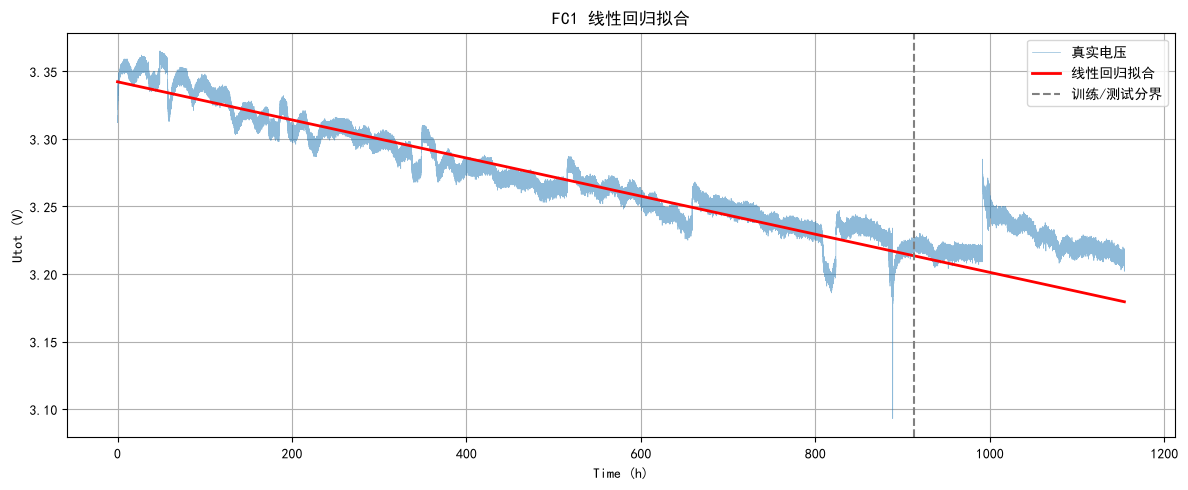

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读入之前存好的完整数据
file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1_full.csv'
df = pd.read_csv(file_path)

# ---- 准备特征和目标 ----
# 特征：只用时间
X = df[['Time (h)']].values
# 目标：总电压
y = df['Utot (V)'].values

# ---- 划分训练集和测试集 ----
# 前 80% 训练，后 20% 测试
split_idx = int(len(df) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print("训练集大小：", X_train.shape)
print("测试集大小：", X_test.shape)

# ---- 训练线性回归 ----
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# ---- 预测 ----
y_pred_train = model_lr.predict(X_train)
y_pred_test = model_lr.predict(X_test)

# ---- 算误差 ----
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_train = mean_absolute_error(y_train, y_pred_train)
mae_test = mean_absolute_error(y_test, y_pred_test)

print("\n线性回归结果：")
print(f"训练集 RMSE = {rmse_train:.6f} V")
print(f"测试集 RMSE = {rmse_test:.6f} V")
print(f"训练集 MAE  = {mae_train:.6f} V")
print(f"测试集 MAE  = {mae_test:.6f} V")
print(f"斜率 = {model_lr.coef_[0]:.8f} V/h")
print(f"截距 = {model_lr.intercept_:.4f} V")

# ---- 画图 ----
plt.figure(figsize=(12, 5))
plt.plot(df['Time (h)'], y, linewidth=0.5, alpha=0.5, label='真实电压')
plt.plot(df['Time (h)'], model_lr.predict(X), linewidth=2, color='red', label='线性回归拟合')
plt.axvline(df['Time (h)'].iloc[split_idx], color='gray', linestyle='--', label='训练/测试分界')
plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('FC1 线性回归拟合')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(r'C:\Users\YOGA\Desktop\训练1.png', dpi=300, bbox_inches='tight')
plt.show()

模型对比（测试集）
线性回归  RMSE = 0.031752 V   MAE = 0.028291 V
随机森林  RMSE = 0.012309 V   MAE = 0.008457 V

RMSE 下降幅度：61.23%

随机森林特征重要性：
  Time (h): 0.9963
  ToutH2 (°C): 0.0017
  HrAIRFC (%): 0.0011
  I (A): 0.0009


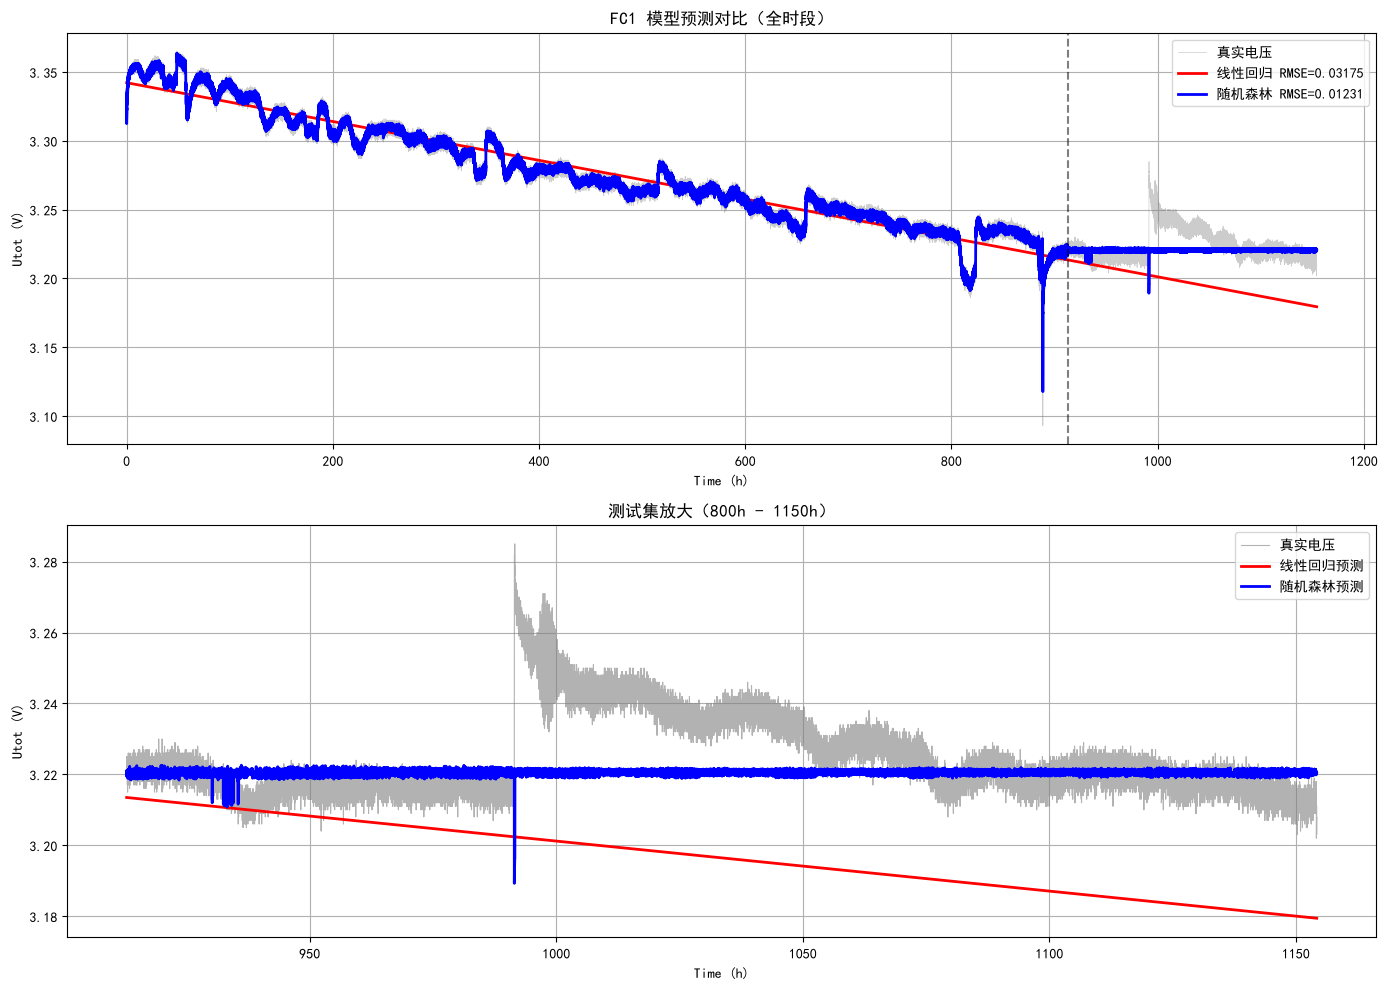


结果已保存到桌面：FC1_baseline_results.csv
图片已保存到桌面：FC1_model_comparison.png


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ========== 1. 读数据 ==========
file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1_full.csv'
df = pd.read_csv(file_path)

# ========== 2. 准备特征 ==========
# 线性回归只用时间（保持之前的对照）
X_lr = df[['Time (h)']].values
# 随机森林用时间 + 温度 + 湿度（多特征）
X_rf = df[['Time (h)', 'ToutH2 (°C)', 'HrAIRFC (%)', 'I (A)']].values
y = df['Utot (V)'].values

# ========== 3. 划分训练/测试 ==========
split_idx = int(len(df) * 0.8)
X_lr_train, X_lr_test = X_lr[:split_idx], X_lr[split_idx:]
X_rf_train, X_rf_test = X_rf[:split_idx], X_rf[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# ========== 4. 训练两个模型 ==========
model_lr = LinearRegression()
model_lr.fit(X_lr_train, y_train)

model_rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
model_rf.fit(X_rf_train, y_train)

# ========== 5. 预测 ==========
y_pred_lr = model_lr.predict(X_lr)
y_pred_rf = model_rf.predict(X_rf)

# ========== 6. 算误差（只在测试集上算） ==========
def metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, mae

rmse_lr, mae_lr = metrics(y_test, y_pred_lr[split_idx:])
rmse_rf, mae_rf = metrics(y_test, y_pred_rf[split_idx:])

print("=" * 50)
print("模型对比（测试集）")
print("=" * 50)
print(f"线性回归  RMSE = {rmse_lr:.6f} V   MAE = {mae_lr:.6f} V")
print(f"随机森林  RMSE = {rmse_rf:.6f} V   MAE = {mae_rf:.6f} V")
print(f"\nRMSE 下降幅度：{(rmse_lr - rmse_rf) / rmse_lr * 100:.2f}%")

# ========== 7. 随机森林特征重要性 ==========
feature_names = ['Time (h)', 'ToutH2 (°C)', 'HrAIRFC (%)', 'I (A)']
importances = model_rf.feature_importances_
print("\n随机森林特征重要性：")
for name, imp in sorted(zip(feature_names, importances), key=lambda x: -x[1]):
    print(f"  {name}: {imp:.4f}")

# ========== 8. 画图对比 ==========
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 上图：两个模型 vs 真实
axes[0].plot(df['Time (h)'], y, linewidth=0.5, alpha=0.4, color='gray', label='真实电压')
axes[0].plot(df['Time (h)'], y_pred_lr, linewidth=2, color='red', label=f'线性回归 RMSE={rmse_lr:.5f}')
axes[0].plot(df['Time (h)'], y_pred_rf, linewidth=2, color='blue', label=f'随机森林 RMSE={rmse_rf:.5f}')
axes[0].axvline(df['Time (h)'].iloc[split_idx], color='black', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Time (h)')
axes[0].set_ylabel('Utot (V)')
axes[0].set_title('FC1 模型预测对比（全时段）')
axes[0].legend()
axes[0].grid(True)

# 下图：只看测试集
axes[1].plot(df['Time (h)'].iloc[split_idx:], y_test, linewidth=0.8, alpha=0.6, color='gray', label='真实电压')
axes[1].plot(df['Time (h)'].iloc[split_idx:], y_pred_lr[split_idx:], linewidth=2, color='red', label='线性回归预测')
axes[1].plot(df['Time (h)'].iloc[split_idx:], y_pred_rf[split_idx:], linewidth=2, color='blue', label='随机森林预测')
axes[1].set_xlabel('Time (h)')
axes[1].set_ylabel('Utot (V)')
axes[1].set_title('测试集放大（800h - 1150h）')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# ========== 9. 保存结果表格 ==========
results = pd.DataFrame({
    '模型': ['线性回归', '随机森林'],
    '特征': ['Time only', 'Time + ToutH2 + HrAIRFC + I'],
    'RMSE (V)': [rmse_lr, rmse_rf],
    'MAE (V)': [mae_lr, mae_rf]
})
results.to_csv(r'C:\Users\YOGA\Desktop\FC1_baseline_results.csv', index=False, encoding='utf-8-sig')
print("\n结果已保存到桌面：FC1_baseline_results.csv")
print("图片已保存到桌面：FC1_model_comparison.png")

#RMSE（均方根误差）：预测值和真实值之差的平方，取平均，再开根号。单位是伏特。对大误差敏感——如果模型偶尔错得很离谱，RMSE 会明显变大。越小越好。

#MAE（平均绝对误差）：预测值和真实值之差的绝对值，取平均。单位是伏特。对每个误差一视同仁——不管错得大还是小，都按绝对值算。越小越好。

#两个一起看：RMSE 和 MAE 差距越大，说明模型存在“偶尔错得很离谱”的情况。你的随机森林 RMSE=0.0123、MAE=0.0085，差距不大，说明误差分布比较均匀，没有极端离群。

#特征重要性：随机森林训练完之后，会输出每个特征对预测的贡献比例，加起来等于 1。值越大，说明这个特征越重要。